In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rcParams
from matplotlib import rc
from matplotlib import colors
import seaborn as sb
from collections import Counter
import glob
import gseapy as gp

#sc.settings.set_figure_params(dpi = 160, color_map = 'RdPu', dpi_save = 300, format = 'pdf')
sc.settings.set_figure_params(dpi = 160, color_map = 'RdYlBu_r', dpi_save = 300, format = 'pdf')

plt.rcParams["figure.figsize"] = [6,6]

In [2]:
import muon as mu

In [3]:
sb.set_palette('colorblind')

In [4]:
# set working directory
%cd /nfs/team205/cs42/HSC/HSC_new_to_transfer/

/nfs/team205/cs42/HSC/HSC_new_to_transfer


In [5]:
from matplotlib import font_manager
font_manager.fontManager.addfont("csv/Helvetica.ttf")
print(font_manager.findfont("Helvetica"))
plt.rcParams["font.sans-serif"] = ["Helvetica"]
plt.rcParams["pdf.fonttype"] = 42

plt.rcParams['savefig.dpi'] = 300

plt.rcParams["axes.grid"] = False
plt.rcParams["pdf.fonttype"] = 42

/nfs/team205/cs42/HSC/HSC_new_to_transfer/csv/Helvetica.ttf


In [6]:
# figure directory
fig_path = 'figure/'
#fig_path = '/home/jovyan/mount/gdrive/HSC/chenqu_jhub/'
sc.settings.figdir = fig_path

# Load data

In [40]:
mdata = mu.read("/lustre/scratch126/cellgen/teichmann/od5/projects/steer_seq/mdata_full.h5mu")

In [41]:
adata = mdata['rna']

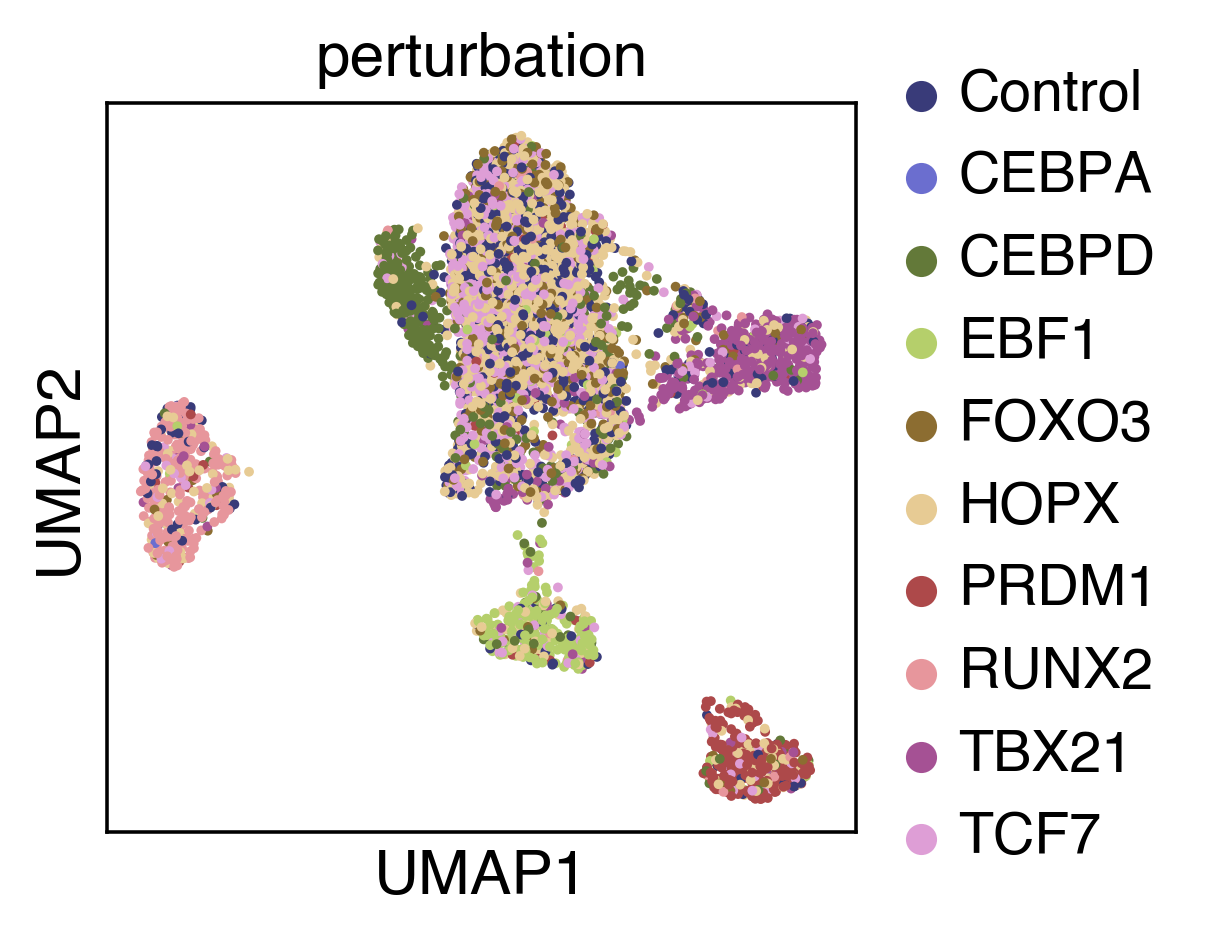

In [10]:
plt.rcParams["figure.figsize"] = [3,3]
sc.pl.umap(adata, color=['perturbation'])

## Enrichment of each perturbation

Computation of enrichment score for each TF O/E vs WT per cell (based on neighbourhoods instead of leiden clustering): 
- sample nhoods 
- for each nhood, each TF O/E, compute a 2x2 table of number of cells within nhood/outside nhood for 1) this TF O/E 2) WT
- chi-square test on this 2x2 table, compute statistic. For this statistic, put a sign in front (higher % of cells in this nhood from TF over WT is +ve), and square root the statistic -> Z-score for enrichment
- project this back to cell, take the weighted average of nhood enrichment Z-score, weighted by nhood size

### 1. Sample nhoods

In [11]:
import pertpy as pt

In [13]:
# recompute neighbourhood to make larger nhoods
sc.pp.neighbors(adata, use_rep='X_pca', n_neighbors=50, random_state=1712)

In [14]:
## Initialize object for Milo analysis
milo = pt.tl.Milo()
midata = milo.load(adata)

In [15]:
milo.make_nhoods(midata["rna"])

In [19]:
midata = milo.count_nhoods(midata, sample_col="sample_ID")

In [20]:
### nhood assignment is stored here
nhoods = midata['rna'].obsm['nhoods']

## 2. Chi-square test for each nhood, each TF O/E

In [36]:
from scipy.stats import chi2_contingency

df_nhood_zscore = pd.DataFrame(index = range(nhoods.shape[1]), columns = adata.obs['perturbation'].cat.categories[1:])

wt = adata.obs['perturbation'] == 'Control'
wt_idx = np.where(wt)[0]
w_total = len(wt_idx)

for smp in df_nhood_zscore.columns: 
    condition = adata.obs['perturbation'] == smp
    # Indices of cells in the sample
    sample_idx = np.where(condition)[0]
    # Total cells in the sample
    n_total = len(sample_idx)

    for i in df_nhood_zscore.index: 
        nhood_col = nhoods[:, i]

        # Extract nhood membership for sample cells - stays sparse
        sample_nhood = nhood_col[sample_idx]
        wt_nhood = nhood_col[wt_idx]

        # Count cells within the nhood
        n_in = sample_nhood.sum()
        w_in = wt_nhood.sum()

        # Cells outside the nhood
        n_out = n_total - n_in
        w_out = w_total - w_in


        ### chi-square test on 2x2 contingency table
        table = np.array([
            [n_in,  n_out],
            [w_in,  w_out]
        ])

        # if both n_in and w_in are 0, can't compute chi-square. set statistic as 0
        if n_in == 0 and w_in == 0:
            df_nhood_zscore.loc[i, smp] = 0 
        
        else:
            chi2, _, _, _ = chi2_contingency(table, correction=False)

            # get the sign of enriched vs wt (+ve) or depleted (-ve)
            sign = np.sign((n_in/n_total) - (w_in/w_total))

            df_nhood_zscore.loc[i, smp] = sign*np.sqrt(chi2)

In [37]:
n_cells, n_nhoods = nhoods.shape

# neighbourhood sizes and inverse weights
sizes = np.asarray(nhoods.sum(axis=0)).ravel()      
inv_sizes = 1.0 / sizes 

# Precompute denominator for ALL cells once: nhoods @ inv_sizes
den_all = nhoods @ inv_sizes                             # (n_cells,)

# container for per-cell scores (or store per-sample into adata.obs)
cell_scores = {}

for smp in df_nhood_zscore.columns:
    z = df_nhood_zscore[smp].astype(float).values   # (n_nhoods,)

    # numerator for ALL cells: N @ (z * inv_sizes)
    num_all = nhoods @ (z * inv_sizes)                   # (n_cells,)

    # weighted average, with safe divide
    score_all = np.zeros(n_cells, dtype=float)
    np.divide(num_all, den_all, out=score_all, where=den_all != 0)

    # optionally restrict to cells of that sample only
    #mask = (adata.obs["sample"] == smp).to_numpy()
    #cell_scores[smp] = score_all[mask]
    # or write full-length vector back to adata.obs
    adata.obs[f"nhood_score_{smp}"] = score_all

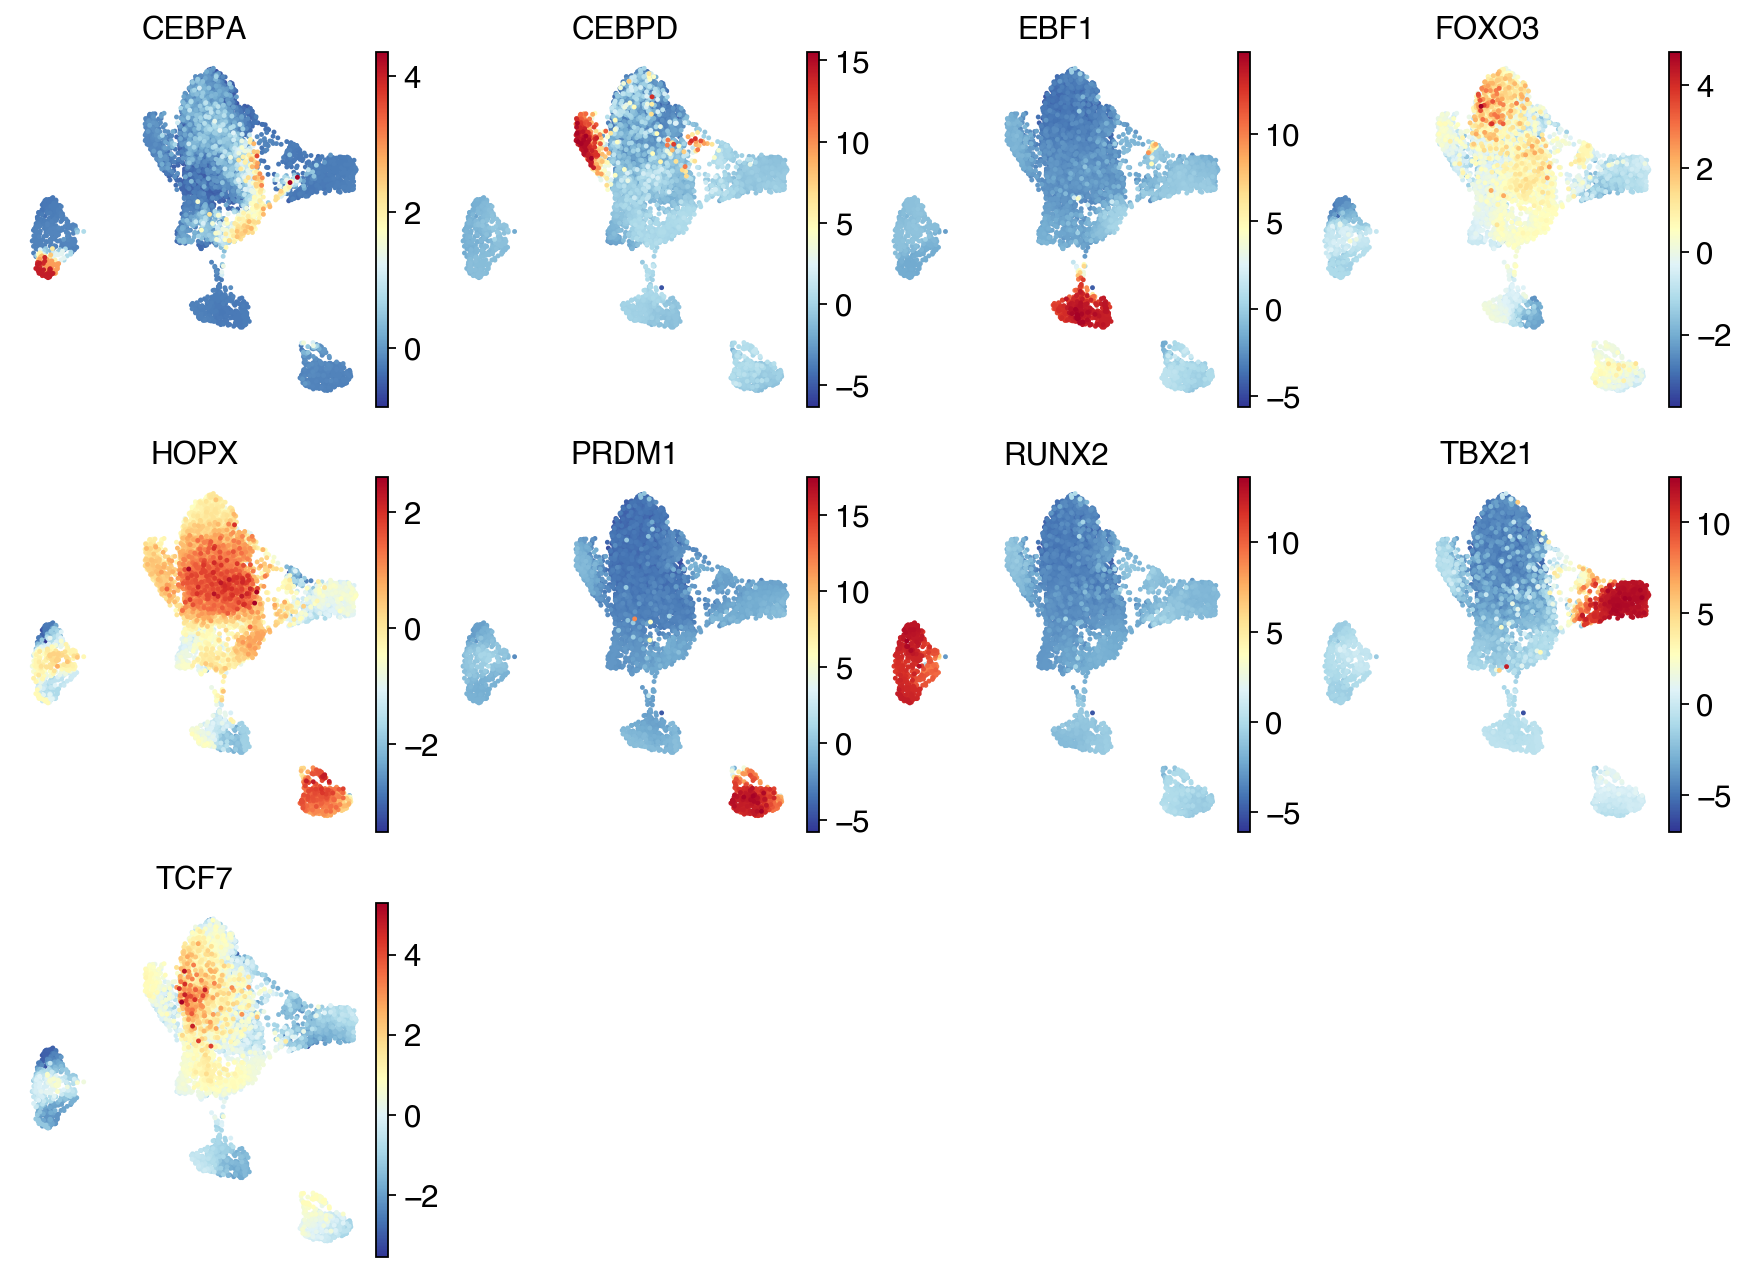

In [38]:
sc.settings.set_figure_params(color_map = 'RdYlBu_r', dpi_save = 300, format = 'pdf')
plt.rcParams["figure.figsize"] = [3,3]

smp_list = df_nhood_zscore.columns
sc.pl.umap(adata, color=["nhood_score_" + smp for smp in smp_list], 
           title=smp_list,
           frameon=False, wspace = 0.1,hspace = 0.2,ncols=4, 
save = 'adata_all_sample_enrichment.pdf')